# 04 · Customer models and scenarios

Questions 43–48 from `analysis_questions.md`.

| Q | Model |
|---|---|
| 43 | **BG/NBD**: probability each customer orders in the next 90 days, and whether they are still "alive" |
| 44 | **BG/NBD + Gamma-Gamma**: expected 12-month gross profit per customer (customer lifetime value, CLV) |
| 45 | Churn-risk list: valuable customers whose silence is longer than their own buying rhythm |
| 46 | Scenario: cap item discounts at 10% and stop stacking discounts |
| 47 | Scenario: 20% of the 80 never-ordered customers convert |
| 48 | Scenario: repeat rate rises from 53% to 60%, and what that does to the PPAC KPI |

BG/NBD and Gamma-Gamma are implemented directly with `scipy` (the same equations as the `lifetimes` package).
Unit of time = **weeks**. Transactions = **revenue orders** (same-day orders merged). Value = **gross profit**.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.optimize import minimize
from scipy.special import gammaln, betaln, hyp2f1, logsumexp
from sklearn.metrics import roc_auc_score
from src.metrics import DATA_DIR, OUTPUT_DIR, DATA_END
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
TEAL, AMBER, NAVY, CORAL, SLATE = "#0E7C86", "#F2A541", "#14213D", "#E4572E", "#5B6C8F"
sns.set_theme(style="whitegrid", palette=[TEAL, AMBER, NAVY, CORAL, SLATE])
FIG = OUTPUT_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
L = lambda v: f"₹{v/1e5:,.1f} L"

cust = pd.read_parquet(DATA_DIR / "customers.parquet")
lines = pd.read_parquet(DATA_DIR / "lines.parquet")
orders = pd.read_parquet(DATA_DIR / "orders.parquet")
ro = orders[orders.is_revenue].copy()

findings = []
def note(q, topic, text):
    findings.append(dict(q=q, topic=topic, finding=text)); print(f"Q{q} · {topic}: {text}")
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## BG/NBD and Gamma-Gamma

In [2]:
def rfm_table(tx: pd.DataFrame, end: pd.Timestamp) -> pd.DataFrame:
    """x = repeat purchases, t_x = time of last purchase (weeks since first), T = age (weeks), m = avg profit per order."""
    daily = tx[tx.order_date <= end].groupby(["customer_id", "order_date"]).gross_profit.sum().reset_index()
    g = daily.groupby("customer_id")
    t = pd.DataFrame({"first": g.order_date.min(), "last": g.order_date.max(), "n": g.size(), "m": g.gross_profit.mean()})
    t["x"] = t.n - 1
    t["t_x"] = (t["last"] - t["first"]).dt.days / 7
    t["T"] = (end - t["first"]).dt.days / 7
    return t

def bgnbd_ll(params, x, tx, T):
    r, alpha, a, b = np.exp(params)
    A1 = gammaln(r + x) - gammaln(r) + r * np.log(alpha)
    A2 = betaln(a, b + x) - betaln(a, b)
    A3 = -(r + x) * np.log(alpha + T)
    A4 = np.where(x > 0, np.log(a) - np.log(np.maximum(b + x - 1, 1e-9)) - (r + x) * np.log(alpha + tx), -np.inf)
    return -(A1 + A2 + logsumexp(np.vstack([A3, A4]), axis=0)).sum()

def fit_bgnbd(t):
    best = None
    for x0 in ([0, 3, 0, 0], [-1, 4, 1, 1], [0.5, 2, -0.5, 0.5]):
        res = minimize(bgnbd_ll, np.array(x0, float), args=(t.x.values, t.t_x.values, t["T"].values), method="Nelder-Mead",
                       options={"maxiter": 20000, "xatol": 1e-8, "fatol": 1e-8})
        if best is None or res.fun < best.fun: best = res
    return dict(zip(["r", "alpha", "a", "b"], np.exp(best.x)))

def p_alive(p, x, tx, T):
    r, alpha, a, b = p["r"], p["alpha"], p["a"], p["b"]
    ratio = np.where(x > 0, (a / (b + x - 1)) * ((alpha + T) / (alpha + tx)) ** (r + x), 0)
    return 1 / (1 + ratio)

def expected_tx(p, t, x, tx, T):
    r, alpha, a, b = p["r"], p["alpha"], p["a"], p["b"]
    hyp = hyp2f1(r + x, b + x, a + b + x - 1, t / (alpha + T + t))
    num = (a + b + x - 1) / (a - 1) * (1 - ((alpha + T) / (alpha + T + t)) ** (r + x) * hyp)
    den = 1 + np.where(x > 0, (a / (b + x - 1)) * ((alpha + T) / (alpha + tx)) ** (r + x), 0)
    return num / den

def p_any_purchase(p, t, x, tx, T):
    """P(at least one purchase in the next t weeks) = P(alive) x (1 - P(no purchase | alive))."""
    r, alpha = p["r"], p["alpha"]
    return p_alive(p, x, tx, T) * (1 - ((alpha + T) / (alpha + T + t)) ** (r + x))

def expected_tx_new(p, t):
    """Expected purchases in t weeks for a brand-new customer (after the first)."""
    r, alpha, a, b = p["r"], p["alpha"], p["a"], p["b"]
    return (a + b - 1) / (a - 1) * (1 - (alpha / (alpha + t)) ** r * hyp2f1(r, b, a + b - 1, t / (alpha + t)))

def gg_ll(params, x, m):
    p, q, v = np.exp(params)
    return -(gammaln(p * x + q) - gammaln(p * x) - gammaln(q) + q * np.log(v) + (p * x - 1) * np.log(m)
             + p * x * np.log(x) - (p * x + q) * np.log(x * m + v)).sum()

def fit_gg(n, m):
    res = minimize(gg_ll, np.log([2, 3, np.mean(m)]), args=(n, m), method="Nelder-Mead", options={"maxiter": 20000})
    return dict(zip(["p", "q", "v"], np.exp(res.x)))

def gg_expected(g, n, m):
    p, q, v = g["p"], g["q"], g["v"]
    pop_mean = v * p / (q - 1)
    w = p * n / (p * n + q - 1)
    return (1 - w) * pop_mean + w * m

## Q43 · Validate on held-out data: calibrate to Apr 2025, predict May–Oct 2025 (26 weeks)

,calibration params
r,1.662
alpha,181.937
a,"156,725.773"
b,"690,298.793"


,actual_hold,pred_hold
x_cap,,
0,0.295,0.171
1,0.186,0.193
2,0.118,0.264
3,0.167,0.338
4,0.000,0.371


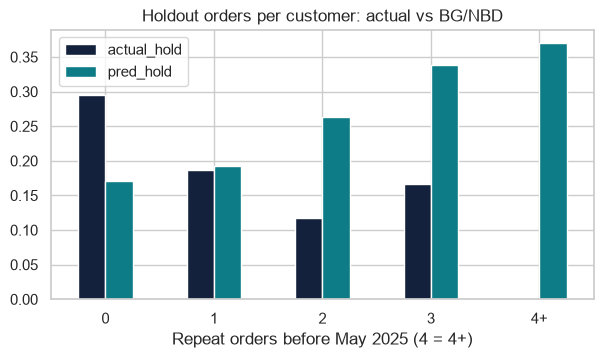

Q43 · Model validation: Calibrated to Apr 2025, BG/NBD predicted 38 repeat orders from existing buyers in May–Oct 2025 vs 47 actual (-20%). Ranking who will buy: AUC 0.45 (recency alone 0.47, frequency alone 0.43). No individual signal: neither the model nor recency or frequency can tell who will buy next. The customer-base simulation (03) forecast aggregate orders better (-1%).


In [3]:
cal_end, hold_end = pd.Timestamp("2025-04-30"), DATA_END
H = (hold_end - cal_end).days / 7
cal = rfm_table(ro, cal_end)
p_cal = fit_bgnbd(cal)
hold = ro[(ro.order_date > cal_end) & (ro.order_date <= hold_end)].groupby("customer_id").order_date.nunique()
cal["actual_hold"] = hold.reindex(cal.index).fillna(0)
cal["pred_hold"] = expected_tx(p_cal, H, cal.x, cal.t_x, cal["T"])
cal["p_any"] = p_any_purchase(p_cal, H, cal.x, cal.t_x, cal["T"])
cal["bought"] = cal.actual_hold > 0
cal["recency_weeks"] = cal["T"] - cal.t_x
auc_model = roc_auc_score(cal.bought, cal.p_any)
auc_recency = roc_auc_score(cal.bought, -cal.recency_weeks)
auc_freq = roc_auc_score(cal.bought, cal.x)
grp = cal.assign(x_cap=cal.x.clip(upper=4)).groupby("x_cap")[["actual_hold", "pred_hold"]].mean()
display(pd.Series(p_cal).to_frame("calibration params"))
display(grp)
fig, ax = plt.subplots(figsize=(7, 3.5))
grp.plot(kind="bar", ax=ax, color=[NAVY, TEAL]); ax.set_xlabel("Repeat orders before May 2025 (4 = 4+)")
ax.set_title("Holdout orders per customer: actual vs BG/NBD"); ax.set_xticklabels([0, 1, 2, 3, "4+"], rotation=0)
save(fig, "q43_bgnbd_holdout")
note(43, "Model validation",
     f"Calibrated to Apr 2025, BG/NBD predicted {cal.pred_hold.sum():.0f} repeat orders from existing buyers in May–Oct 2025 vs "
     f"{cal.actual_hold.sum():.0f} actual ({cal.pred_hold.sum()/cal.actual_hold.sum()-1:+.0%}). Ranking who will buy: AUC {auc_model:.2f} "
     f"(recency alone {auc_recency:.2f}, frequency alone {auc_freq:.2f}). "
     f"{'Useful for prioritising, not for certainty.' if auc_model >= .6 else 'No individual signal: neither the model nor recency or frequency can tell who will buy next. The customer-base simulation (03) forecast aggregate orders better (-1%).'}")

### Is there any difference between customers to model? (Poisson dispersion test)

In [4]:
from scipy import stats
t_all = rfm_table(ro, DATA_END)
lam = t_all.x.sum() / t_all["T"].sum()
expct = lam * t_all["T"]
chi = ((t_all.x - expct) ** 2 / expct).sum(); dof = len(t_all) - 1
dispersion, p_disp = chi / dof, 1 - stats.chi2.cdf(chi, dof)
print(f"Common repeat rate {lam*52/12:.2%} per month; dispersion {dispersion:.2f} (1.0 = every buyer has the same rate), p={p_disp:.2f}")
note(43, "Customer heterogeneity",
     f"Repeat orders per buyer match a single shared Poisson rate of {lam*52/12:.1%}/month (dispersion {dispersion:.2f}, p={p_disp:.2f}). "
     f"BG/NBD agrees: its fitted parameters collapse to one rate with no drop-out. Buyers do not differ in how often they buy, "
     f"and nobody measurably 'churns': every buyer is equally likely to order next month.")

Common repeat rate 3.60% per month; dispersion 1.03 (1.0 = every buyer has the same rate), p=0.37
Q43 · Customer heterogeneity: Repeat orders per buyer match a single shared Poisson rate of 3.6%/month (dispersion 1.03, p=0.37). BG/NBD agrees: its fitted parameters collapse to one rate with no drop-out. Buyers do not differ in how often they buy, and nobody measurably 'churns': every buyer is equally likely to order next month.


## Q43 · Score every customer as of 31 Oct 2025

In [5]:
full = rfm_table(ro, DATA_END)
P = fit_bgnbd(full)
full["p_alive"] = p_alive(P, full.x, full.t_x, full["T"])
full["p_order_90d"] = p_any_purchase(P, 90 / 7, full.x, full.t_x, full["T"])
full["exp_orders_12m"] = expected_tx(P, 52, full.x, full.t_x, full["T"])
display(pd.Series(P).to_frame("final params"))
display(full[["p_alive", "p_order_90d", "exp_orders_12m"]].describe())
top = full.p_order_90d.sort_values(ascending=False)
note(43, "90-day purchase probability",
     f"Average P(order in next 90 days) {full.p_order_90d.mean():.0%} (range {full.p_order_90d.min():.0%}–{full.p_order_90d.max():.0%}). "
     f"Expected orders from all {len(full)} buyers in the next 90 days ≈ {expected_tx(P, 90/7, full.x, full.t_x, full['T']).sum():.0f}. "
     f"P(alive) is ~{full.p_alive.median():.0%} for everyone. Scores are near-identical, so **do not build propensity-based targeting** "
     f"on this data: give every buyer the same follow-up cadence.")

,final params
r,33.978
alpha,"4,081.294"
a,15.338
b,"9,352,471.704"


,p_alive,p_order_90d,exp_orders_12m
count,216.000,216.000,216.000
mean,1.000,0.101,0.433
std,0.000,0.002,0.011
min,1.000,0.098,0.418
25%,1.000,0.099,0.424
50%,1.000,0.101,0.432
75%,1.000,0.103,0.439
max,1.000,0.110,0.472


Q43 · 90-day purchase probability: Average P(order in next 90 days) 10% (range 10%–11%). Expected orders from all 216 buyers in the next 90 days ≈ 23. P(alive) is ~100% for everyone. Scores are near-identical, so **do not build propensity-based targeting** on this data: give every buyer the same follow-up cadence.


## Q44 · 12-month customer lifetime value (gross profit)

,Gamma-Gamma params
p,1.568
q,75.514
v,"3,542,209.238"


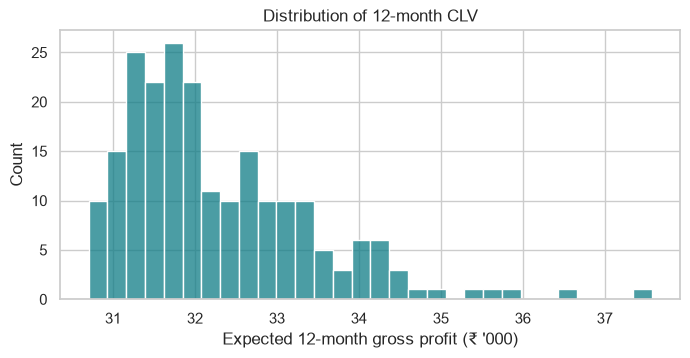

Q44 · 12-month CLV: Expected gross profit from existing buyers over the next 12 months ≈ ₹69.7 L (median ₹31,897 per buyer, top ₹37,579). Top 20% of buyers hold only 21% of it: future value is spread almost evenly, and individual differences come only from past order value, heavily shrunk. The total is the useful number (cross-check: 216 buyers x 3.6%/month x 12 x avg profit/order). Frequency vs order-value correlation 0.09 (independent, so Gamma-Gamma is valid). No discounting applied over 12 months.


In [6]:
corr = full.loc[full.x > 0, ["x", "m"]].corr().iloc[0, 1]
mpos = full[full.m > 0]
G = fit_gg(mpos.n.values.astype(float), mpos.m.values)
full["exp_profit_per_order"] = gg_expected(G, full.n, full.m.clip(lower=1))
full["clv_12m"] = full.exp_orders_12m * full.exp_profit_per_order
s = full.clv_12m.sort_values(ascending=False)
top20 = s.iloc[: int(len(s) * .2)].sum() / s.sum()
display(pd.Series(G).to_frame("Gamma-Gamma params"))
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(full.clv_12m / 1e3, bins=30, ax=ax, color=TEAL); ax.set_xlabel("Expected 12-month gross profit (₹ '000)")
ax.set_title("Distribution of 12-month CLV"); save(fig, "q44_clv")
note(44, "12-month CLV",
     f"Expected gross profit from existing buyers over the next 12 months ≈ {L(full.clv_12m.sum())} "
     f"(median ₹{full.clv_12m.median():,.0f} per buyer, top ₹{full.clv_12m.max():,.0f}). Top 20% of buyers hold only {top20:.0%} of it: "
     f"future value is spread almost evenly, and individual differences come only from past order value, heavily shrunk. "
     f"The total is the useful number (cross-check: 216 buyers x 3.6%/month x 12 x avg profit/order). "
     f"Frequency vs order-value correlation {corr:.2f} ({'independent, so Gamma-Gamma is valid' if abs(corr) < .3 else 'check independence'}). "
     f"No discounting applied over 12 months.")

## Q45 · Churn-risk list

In [7]:
seq = ro.groupby(["customer_id", "order_date"]).size().reset_index().sort_values(["customer_id", "order_date"])
seq["gap"] = seq.groupby("customer_id").order_date.diff().dt.days
med_gap = seq.groupby("customer_id").gap.median()
full["own_median_gap_days"] = med_gap
full["days_silent"] = (DATA_END - full["last"]).dt.days
full["silence_ratio"] = full.days_silent / full.own_median_gap_days
risk = full[(full.x >= 1) & ((full.silence_ratio >= 2) | (full.p_alive < .5))].copy()
risk["value_at_stake_12m"] = risk.n.clip(upper=12) / ((full["T"] / 52).clip(lower=1)).reindex(risk.index) * risk.exp_profit_per_order
risk = risk.sort_values("value_at_stake_12m", ascending=False)
info = cust.set_index("customer_id")[["first_name", "last_name", "segment", "state", "city"]]
risk_out = risk.join(info)[["first_name", "last_name", "segment", "state", "n", "last", "days_silent", "own_median_gap_days",
                            "silence_ratio", "p_alive", "value_at_stake_12m"]]
display(risk_out.drop(columns=["first_name", "last_name"]).head(15))   # names stay in the local CSV only
risk_out.to_csv(OUTPUT_DIR / "churn_risk_customers.csv")
# Does the silence rule predict anything? Apply it at Apr 2025 and check May-Oct 2025 purchases.
d_ = ro.groupby(["customer_id", "order_date"]).size().reset_index()
dc = d_[d_.order_date <= cal_end].sort_values(["customer_id", "order_date"])
dc["gap"] = dc.groupby("customer_id").order_date.diff().dt.days
n_c = dc.groupby("customer_id").size(); rep_ids = n_c[n_c >= 2].index
ratio_c = ((cal_end - dc.groupby("customer_id").order_date.max()).dt.days / dc.groupby("customer_id").gap.median()).reindex(rep_ids)
val = pd.DataFrame({"flagged": ratio_c >= 2, "bought_next_6m": rep_ids.isin(d_[d_.order_date > cal_end].customer_id)}, index=rep_ids)
vt = val.groupby("flagged").bought_next_6m.agg(["mean", "size"]); display(vt)
p_flag = stats.fisher_exact(pd.crosstab(val.flagged, val.bought_next_6m))[1]
note(45, "Churn risk",
     f"{len(risk)} repeat buyers are silent for 2x+ their own usual gap (historical run-rate ≈ {L(risk.value_at_stake_12m.sum())}/yr). "
     f"But the rule does not predict: applied at Apr 2025, flagged buyers ordered in the next 6 months at {vt.loc[True,'mean']:.0%} vs "
     f"{vt.loc[False,'mean']:.0%} for others (p={p_flag:.2f}). Long silence is normal for a ~4%/month buyer, not a churn signal. "
     f"Use output/churn_risk_customers.csv as a re-engagement contact list, not as a risk prediction.")

,segment,state,n,last,days_silent,own_median_gap_days,silence_ratio,p_alive,value_at_stake_12m
customer_id,,,,,,,,,
CUST0114,Wholesale,Karnataka,3,2025-03-25,220,97.000,2.268,1.000,"194,555.722"
CUST0166,Retail,Gujarat,3,2024-12-13,322,66.500,4.842,1.000,"182,498.263"
CUST0058,Retail,Gujarat,5,2025-01-24,280,115.500,2.424,1.000,"171,040.319"
CUST0129,Wholesale,Maharashtra,5,2024-09-06,420,29.500,14.237,1.000,"163,811.002"
CUST0080,Retail,Telangana,3,2025-02-04,269,114.000,2.360,1.000,"159,822.234"
CUST0092,Retail,Delhi,2,2025-03-15,230,2.000,115.000,1.000,"148,857.081"
CUST0137,Retail,Andhra Pradesh,2,2025-05-12,172,63.000,2.730,1.000,"147,132.600"
CUST0095,Retail,Maharashtra,4,2025-04-10,204,65.000,3.138,1.000,"146,898.092"
CUST0142,Retail,Madhya Pradesh,2,2025-06-12,141,27.000,5.222,1.000,"145,702.698"


,mean,size
flagged,,
False,0.175,57
True,0.111,27


Q45 · Churn risk: 38 repeat buyers are silent for 2x+ their own usual gap (historical run-rate ≈ ₹41.0 L/yr). But the rule does not predict: applied at Apr 2025, flagged buyers ordered in the next 6 months at 11% vs 18% for others (p=0.53). Long silence is normal for a ~4%/month buyer, not a churn signal. Use output/churn_risk_customers.csv as a re-engagement contact list, not as a risk prediction.


## Scenarios

### Q46 · Cap item discounts at 10% and stop stacking (last 12 months re-priced)

In [8]:
l12 = lines[lines.is_revenue & (lines.order_date > DATA_END - pd.DateOffset(months=12))].copy()
def reprice(df, item_cap=10, no_stack=True):
    d = df.copy()
    d["item_d"] = d.item_discount_percent.clip(upper=item_cap)
    d["order_d"] = np.where(no_stack & (d.item_d > 0), 0, d.discount_percent)
    d["ns_new"] = d.gross_amount * (1 - d.item_d / 100) * (1 - d.order_d / 100)
    d["gp_new"] = d.ns_new - d.cogs
    return d
base_gp = l12.gross_profit.sum()
res = []
for cap, ns in [(10, False), (10, True), (5, True)]:
    d = reprice(l12, cap, ns)
    affected = (d.ns_new - d.net_sales).abs() > 1
    uplift = d.gp_new.sum() - base_gp
    # breakeven: volume loss on affected lines that wipes out the uplift
    affected_gp_new = d.loc[affected, "gp_new"].sum()
    breakeven = uplift / affected_gp_new if affected_gp_new else np.nan
    for elast in (0, .05, .10, .20):
        res.append(dict(rule=f"item cap {cap}%" + (", no stacking" if ns else ""), volume_loss_on_affected=elast,
                        gp_uplift=uplift - elast * affected_gp_new, uplift_pct=(uplift - elast * affected_gp_new) / base_gp,
                        affected_lines=int(affected.sum()), breakeven_volume_loss=breakeven))
R46 = pd.DataFrame(res)
display(R46.pivot(index="rule", columns="volume_loss_on_affected", values="uplift_pct").style.format("{:+.1%}"))
r = R46[(R46.rule == "item cap 10%, no stacking")]
note(46, "Discount cap",
     f"Last 12 months re-priced with item discounts capped at 10% and no stacking: gross profit +{L(r.gp_uplift.iloc[0])} "
     f"({r.uplift_pct.iloc[0]:+.1%}) if volume holds, {r.uplift_pct.iloc[2]:+.1%} if affected orders fall 10%. "
     f"It only stops paying off if {r.breakeven_volume_loss.iloc[0]:.0%} of affected volume is lost. EDA Q28 found discounts do not "
     f"drive repeat buying, so a large loss is unlikely.")

volume_loss_on_affected,0.000000,0.050000,0.100000,0.200000
rule,,,,
item cap 10%,+3.7%,+2.9%,+2.1%,+0.6%
"item cap 10%, no stacking",+12.8%,+11.0%,+9.2%,+5.6%
"item cap 5%, no stacking",+18.8%,+16.6%,+14.3%,+9.7%


Q46 · Discount cap: Last 12 months re-priced with item discounts capped at 10% and no stacking: gross profit +₹12.2 L (+12.8%) if volume holds, +9.2% if affected orders fall 10%. It only stops paying off if 36% of affected volume is lost. EDA Q28 found discounts do not drive repeat buying, so a large loss is unlikely.


### Q47 · 20% of the 80 never-ordered customers convert

In [9]:
never = int((cust.lifetime_orders == 0).sum())
conv = round(never * .2)
first_orders = ro.sort_values("order_date").groupby("customer_id").head(1)
first_gp = first_orders[first_orders.order_date > DATA_END - pd.DateOffset(months=24)].gross_profit.mean()
pop_aov_gp = gg_expected(G, np.array([1.0]), np.array([full.m.mean()]))[0]
repeat_12m_new = expected_tx_new(P, 52)
uplift_first = conv * first_gp
uplift_repeat = conv * repeat_12m_new * pop_aov_gp
note(47, "Activation",
     f"{conv} of {never} never-ordered customers converting adds ≈ {L(uplift_first)} from first orders (avg first-order profit "
     f"₹{first_gp:,.0f}) plus ≈ {L(uplift_repeat)} from their repeat orders in the following 12 months "
     f"({repeat_12m_new:.2f} expected repeats each): ≈ {L(uplift_first + uplift_repeat)} in total, about "
     f"{(uplift_first + uplift_repeat) / 9_690_000:.0%} of the 2026 base forecast.")

Q47 · Activation: 16 of 80 never-ordered customers converting adds ≈ ₹10.8 L from first orders (avg first-order profit ₹67,772) plus ≈ ₹5.2 L from their repeat orders in the following 12 months (0.43 expected repeats each): ≈ ₹16.0 L in total, about 17% of the 2026 base forecast.


### Q48 · Repeat rate 53% → 60%: profit and the PPAC KPI

In [10]:
buyers = int((cust.lifetime_orders > 0).sum()); rec = int((cust.customer_type == "Recurring").sum())
target_rec = round(buyers * .60); extra = target_rec - rec
gp_per_order = ro[ro.order_date > DATA_END - pd.DateOffset(months=12)].gross_profit.mean()
uplift = extra * gp_per_order                     # each converted one-time buyer places one more order
# PPAC effect in a year: forecast 2026 scenario A (from 03_forecast): GP ~₹96.9 L, PPAC ~₹92,247 -> active ≈ GP/PPAC
gp26, ppac26 = 9_688_851, 92_247
act26 = gp26 / ppac26
ppac_new = (gp26 + uplift) / (act26 + extra)
note(48, "Repeat rate",
     f"Raising the repeat rate from {rec/buyers:.0%} to 60% means {extra} more of today's one-time buyers ordering again. "
     f"At ₹{gp_per_order:,.0f} profit per order that adds ≈ {L(uplift)} of profit. But PPAC would move from ₹{ppac26:,} to "
     f"≈ ₹{ppac_new:,.0f}: it FALLS, because each re-activated buyer adds one average order but a whole extra 'active customer'. "
     f"PPAC rewards deepening existing relationships, not widening them; track it alongside total gross profit and repeat rate.")

Q48 · Repeat rate: Raising the repeat rate from 53% to 60% means 16 more of today's one-time buyers ordering again. At ₹72,924 profit per order that adds ≈ ₹11.7 L of profit. But PPAC would move from ₹92,247 to ≈ ₹89,693: it FALLS, because each re-activated buyer adds one average order but a whole extra 'active customer'. PPAC rewards deepening existing relationships, not widening them; track it alongside total gross profit and repeat rate.


## Outputs

In [11]:
scores = full.join(info).join(cust.set_index("customer_id")[["customer_type"]])
rfm = pd.read_csv(OUTPUT_DIR / "rfm_segments.csv").set_index("customer_id")[["segment"]].rename(columns={"segment": "rfm_segment"})
scores = scores.join(rfm)
scores["churn_risk"] = scores.index.isin(risk.index)
cols = ["first_name", "last_name", "segment", "state", "customer_type", "rfm_segment", "n", "first", "last", "days_silent",
        "p_alive", "p_order_90d", "exp_orders_12m", "exp_profit_per_order", "clv_12m", "churn_risk"]
scores[cols].sort_values("clv_12m", ascending=False).to_csv(OUTPUT_DIR / "customer_scores.csv")
R46.to_csv(OUTPUT_DIR / "scenario_discount_cap.csv", index=False)
ann = pd.read_csv(OUTPUT_DIR / "pbi_forecast_2026.csv")
gpA = ann[(ann.metric == "Gross profit") & ann.scenario.str.startswith("A")].p50.iloc[0]
gpB = ann[(ann.metric == "Gross profit") & ann.scenario.str.startswith("B")].p50.iloc[0]
r10 = R46[R46.rule == "item cap 10%, no stacking"]
levers = pd.DataFrame([
    dict(lever="Discount cap (10%, no stacking)", uplift_low=r10.gp_uplift.iloc[2], uplift_high=r10.gp_uplift.iloc[0],
         confidence="High", cost="None", basis="Last 12 months re-priced; low = affected orders fall 10%"),
    dict(lever="Activate 20% of never-ordered", uplift_low=uplift_first, uplift_high=uplift_first + uplift_repeat,
         confidence="Medium", cost="Low", basis="16 first orders, plus their repeat orders within 12 months"),
    dict(lever="Repeat rate 53% to 60%", uplift_low=uplift, uplift_high=uplift, confidence="Medium", cost="Low to medium",
         basis="16 one-time buyers order once more; note PPAC falls"),
    dict(lever="Restart sign-ups (2024 pace)", uplift_low=gpB - gpA, uplift_high=gpB - gpA, confidence="Unknown cause", cost="Marketing spend",
         basis="Forecast scenario B minus A, 2026"),
])
levers["uplift_mid"] = (levers.uplift_low + levers.uplift_high) / 2
levers.to_csv(OUTPUT_DIR / "pbi_levers.csv", index=False)
display(levers)
F = pd.DataFrame(findings); F.to_csv(OUTPUT_DIR / "customer_model_findings.csv", index=False)
pd.set_option("display.max_colwidth", None); F

,lever,uplift_low,uplift_high,confidence,cost,basis,uplift_mid
0,"Discount cap (10%, no stacking)","875,110.949","1,215,946.851",High,None,Last 12 months re-priced; low = affected order...,"1,045,528.900"
1,Activate 20% of never-ordered,"1,084,346.262","1,600,346.830",Medium,Low,"16 first orders, plus their repeat orders with...","1,342,346.546"
2,Repeat rate 53% to 60%,"1,166,780.579","1,166,780.579",Medium,Low to medium,16 one-time buyers order once more; note PPAC ...,"1,166,780.579"
3,Restart sign-ups (2024 pace),"1,091,764.961","1,091,764.961",Unknown cause,Marketing spend,"Forecast scenario B minus A, 2026","1,091,764.961"


,q,topic,finding
0,43,Model validation,"Calibrated to Apr 2025, BG/NBD predicted 38 repeat orders from existing buyers in May–Oct 2025 vs 47 actual (-20%). Ranking who will buy: AUC 0.45 (recency alone 0.47, frequency alone 0.43). No individual signal: neither the model nor recency or frequency can tell who will buy next. The customer-base simulation (03) forecast aggregate orders better (-1%)."
1,43,Customer heterogeneity,"Repeat orders per buyer match a single shared Poisson rate of 3.6%/month (dispersion 1.03, p=0.37). BG/NBD agrees: its fitted parameters collapse to one rate with no drop-out. Buyers do not differ in how often they buy, and nobody measurably 'churns': every buyer is equally likely to order next month."
2,43,90-day purchase probability,"Average P(order in next 90 days) 10% (range 10%–11%). Expected orders from all 216 buyers in the next 90 days ≈ 23. P(alive) is ~100% for everyone. Scores are near-identical, so **do not build propensity-based targeting** on this data: give every buyer the same follow-up cadence."
3,44,12-month CLV,"Expected gross profit from existing buyers over the next 12 months ≈ ₹69.7 L (median ₹31,897 per buyer, top ₹37,579). Top 20% of buyers hold only 21% of it: future value is spread almost evenly, and individual differences come only from past order value, heavily shrunk. The total is the useful number (cross-check: 216 buyers x 3.6%/month x 12 x avg profit/order). Frequency vs order-value correlation 0.09 (independent, so Gamma-Gamma is valid). No discounting applied over 12 months."
4,45,Churn risk,"38 repeat buyers are silent for 2x+ their own usual gap (historical run-rate ≈ ₹41.0 L/yr). But the rule does not predict: applied at Apr 2025, flagged buyers ordered in the next 6 months at 11% vs 18% for others (p=0.53). Long silence is normal for a ~4%/month buyer, not a churn signal. Use output/churn_risk_customers.csv as a re-engagement contact list, not as a risk prediction."
5,46,Discount cap,"Last 12 months re-priced with item discounts capped at 10% and no stacking: gross profit +₹12.2 L (+12.8%) if volume holds, +9.2% if affected orders fall 10%. It only stops paying off if 36% of affected volume is lost. EDA Q28 found discounts do not drive repeat buying, so a large loss is unlikely."
6,47,Activation,"16 of 80 never-ordered customers converting adds ≈ ₹10.8 L from first orders (avg first-order profit ₹67,772) plus ≈ ₹5.2 L from their repeat orders in the following 12 months (0.43 expected repeats each): ≈ ₹16.0 L in total, about 17% of the 2026 base forecast."
7,48,Repeat rate,"Raising the repeat rate from 53% to 60% means 16 more of today's one-time buyers ordering again. At ₹72,924 profit per order that adds ≈ ₹11.7 L of profit. But PPAC would move from ₹92,247 to ≈ ₹89,693: it FALLS, because each re-activated buyer adds one average order but a whole extra 'active customer'. PPAC rewards deepening existing relationships, not widening them; track it alongside total gross profit and repeat rate."
